# Section B

**Candidate Name:** Ajmal Razaq  
**Roll Number:** 23F-0524  
**Section:** Section B  
**GitHub Repository:** https://github.com/theajmalrazaq/dlpass

In [1]:
import os
import time
import copy
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF

# Hardware Acceleration Setup (CUDA / CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Execution Device: {device}')
print(f'PyTorch Version: {torch.__version__} | Torchvision Version: {torchvision.__version__}')


Execution Device: cpu
PyTorch Version: 2.14.1+cpu | Torchvision Version: 0.29.1+cpu


# Inception-style CNN Architecture (< 1,000,000 parameters)
Our model, **CIFARInceptionNet**, uses a dual-stage convolutional stem, two multi-scale Inception blocks with 1x1, 3x3, and 5x5 filters, followed by a refinement convolution, global average pooling, dropout (0.4), and a linear classification head. It contains exactly **365,290** trainable parameters.

In [2]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, k=3, s=1, p=1):
        super().__init__()
        self.op = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=p, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.op(x)

class InceptionLayer(nn.Module):
    def __init__(self, in_c, c1, c3_r, c3, c5_r, c5, pool_p):
        super().__init__()
        self.branch1 = ConvBlock(in_c, c1, k=1, p=0)
        self.branch2 = nn.Sequential(ConvBlock(in_c, c3_r, k=1, p=0), ConvBlock(c3_r, c3, k=3, p=1))
        self.branch3 = nn.Sequential(ConvBlock(in_c, c5_r, k=1, p=0), ConvBlock(c5_r, c5, k=5, p=2))
        self.branch4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), ConvBlock(in_c, pool_p, k=1, p=0))
    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x), self.branch4(x)], dim=1)

class CIFARInceptionNet(nn.Module):
    def __init__(self, num_classes=10, dropout=0.4):
        super().__init__()
        self.stem = nn.Sequential(
            ConvBlock(3, 32, k=3, p=1),
            ConvBlock(32, 64, k=3, p=1),
            nn.MaxPool2d(2, 2)
        )
        self.stage1 = InceptionLayer(64, c1=32, c3_r=16, c3=32, c5_r=16, c5=32, pool_p=16)
        self.down1 = nn.MaxPool2d(2, 2)
        self.stage2 = InceptionLayer(112, c1=48, c3_r=32, c3=64, c5_r=16, c5=32, pool_p=16)
        self.down2 = nn.MaxPool2d(2, 2)
        self.refine = ConvBlock(160, 192, k=3, p=1)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.drop = nn.Dropout(p=dropout)
        self.head = nn.Linear(192, num_classes)
        self._reset_weights()

    def _reset_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        x = self.stem(x)
        x = self.down1(self.stage1(x))
        x = self.down2(self.stage2(x))
        x = self.refine(x)
        x = self.pool(x).flatten(1)
        return self.head(self.drop(x))

model = CIFARInceptionNet()
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total Trainable Parameters: {total_params:,}')
assert total_params <= 1_000_000, 'Exceeded parameter budget!'


Total Trainable Parameters: 365,290


In [3]:
# Seeded Dataset Splitting and Corrupted Test Generation
CIFAR_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR_STD = [0.2470, 0.2435, 0.2616]
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

cifar_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
cifar_test = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

torch.manual_seed(42)
np.random.seed(42)
targets = np.array(cifar_train.targets)
train_idx, val_idx = [], []
for c in range(10):
    c_idx = np.where(targets == c)[0]
    np.random.shuffle(c_idx)
    train_idx.extend(c_idx[:40])
    val_idx.extend(c_idx[40:50])

train_imgs = [cifar_train.data[i] for i in train_idx]
train_lbls = [cifar_train.targets[i] for i in train_idx]
val_imgs = [cifar_train.data[i] for i in val_idx]
val_lbls = [cifar_train.targets[i] for i in val_idx]
clean_test_imgs = list(cifar_test.data)
clean_test_lbls = list(cifar_test.targets)

print(f'Data prepared: {len(train_imgs)} train, {len(val_imgs)} validation, {len(clean_test_imgs)} test images.')


Files already downloaded and verified
Files already downloaded and verified
Data prepared: 400 train, 100 validation, 10000 test images.


In [4]:
class CIFARSubsetDataset(torch.utils.data.Dataset):
    def __init__(self, imgs, labels, transform=None):
        self.imgs = imgs
        self.labels = labels
        self.transform = transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        im = Image.fromarray(self.imgs[i])
        y = self.labels[i]
        if self.transform:
            im = self.transform(im)
        return im, y

class AdditiveNoiseTensor:
    def __init__(self, std=0.035):
        self.std = std
    def __call__(self, t):
        return torch.clamp(t + torch.randn_like(t) * self.std, 0.0, 1.0)

def build_augmentation_transform(config_name):
    norm = T.Normalize(CIFAR_MEAN, CIFAR_STD)
    eval_tf = T.Compose([T.ToTensor(), norm])
    if config_name == 'No augmentation':
        train_tf = T.Compose([T.ToTensor(), norm])
    elif config_name == 'Geometric only':
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ToTensor(), norm
        ])
    elif config_name == 'Photometric only':
        train_tf = T.Compose([
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.25),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.2)),
            T.ToTensor(), AdditiveNoiseTensor(std=0.035), norm
        ])
    elif config_name == 'Geometric + photometric':
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.25),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.2)),
            T.ToTensor(), norm
        ])
    elif config_name == '+ Cutout / Random Erasing':
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.25),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.2)),
            T.ToTensor(), norm,
            T.RandomErasing(p=0.5, scale=(0.08, 0.25), ratio=(0.6, 1.7), value=0)
        ])
    elif config_name in ['+ Mixup or CutMix + label smoothing', 'Final model']:
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.25),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.2)),
            T.ToTensor(), norm,
            T.RandomErasing(p=0.5, scale=(0.08, 0.25), ratio=(0.6, 1.7), value=0)
        ])
    else:
        raise ValueError(f'Unknown config: {config_name}')
    return train_tf, eval_tf

def prepare_data_loaders(config_name, batch_size=32):
    train_tf, eval_tf = build_augmentation_transform(config_name)
    return {
        'train': torch.utils.data.DataLoader(CIFARSubsetDataset(train_imgs, train_lbls, train_tf), batch_size=batch_size, shuffle=True),
        'val': torch.utils.data.DataLoader(CIFARSubsetDataset(val_imgs, val_lbls, eval_tf), batch_size=batch_size, shuffle=False),
        'clean_test': torch.utils.data.DataLoader(CIFARSubsetDataset(clean_test_imgs, clean_test_lbls, eval_tf), batch_size=64, shuffle=False),
        'shifted_test': torch.utils.data.DataLoader(CIFARSubsetDataset(shifted_test_imgs, clean_test_lbls, eval_tf), batch_size=64, shuffle=False),
        'hidden_test': torch.utils.data.DataLoader(CIFARSubsetDataset(hidden_test_imgs, clean_test_lbls, eval_tf), batch_size=64, shuffle=False)
    }

def apply_mixup_blend(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    perm = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1.0 - lam) * x[perm], y, y[perm], lam

def mixup_loss_fn(criterion, preds, ya, yb, lam):
    return lam * criterion(preds, ya) + (1.0 - lam) * criterion(preds, yb)

def execute_training_run(model, loaders, epochs=45, lr=0.003, weight_decay=5e-4, use_mixup=False, label_smoothing=0.0, patience=15):
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    best_v_acc, best_weights, no_imp = -1.0, copy.deepcopy(model.state_dict()), 0
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(1, epochs + 1):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in loaders['train']:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            if use_mixup:
                mx, ya, yb, lam = apply_mixup_blend(x, y, alpha=0.2)
                out = model(mx)
                loss = mixup_loss_fn(criterion, out, ya, yb, lam)
                pred = out.argmax(1)
                correct += (lam * pred.eq(ya).sum().float() + (1.0 - lam) * pred.eq(yb).sum().float()).item()
            else:
                out = model(x)
                loss = criterion(out, y)
                correct += out.argmax(1).eq(y).sum().item()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * x.size(0)
            total += y.size(0)
        scheduler.step()
        model.eval()
        v_loss_sum, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for vx, vy in loaders['val']:
                vx, vy = vx.to(device), vy.to(device)
                vout = model(vx)
                v_loss_sum += criterion(vout, vy).item() * vx.size(0)
                v_corr += vout.argmax(1).eq(vy).sum().item()
                v_tot += vy.size(0)
        val_acc = (v_corr / v_tot) * 100.0
        hist['train_loss'].append(loss_sum / total)
        hist['train_acc'].append((correct / total) * 100.0)
        hist['val_loss'].append(v_loss_sum / v_tot)
        hist['val_acc'].append(val_acc)
        if val_acc > best_v_acc:
            best_v_acc, best_weights, no_imp = val_acc, copy.deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        if no_imp >= patience and ep >= 25:
            break
    model.load_state_dict(best_weights)
    return model, hist

@torch.no_grad()
def evaluate_metric(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += model(x).argmax(1).eq(y).sum().item()
        total += y.size(0)
    return (correct / total) * 100.0

print('DataLoaders and training engine initialized successfully.')


DataLoaders and training engine initialized successfully.


## Part A

Baseline Results (Seed 42):
  Train Accuracy:        99.50%
  Validation Accuracy:   54.00%
  Clean Test Accuracy:   40.60%
  Shifted Test Accuracy: 14.13%
  Robustness Gap (Δ):    26.47%


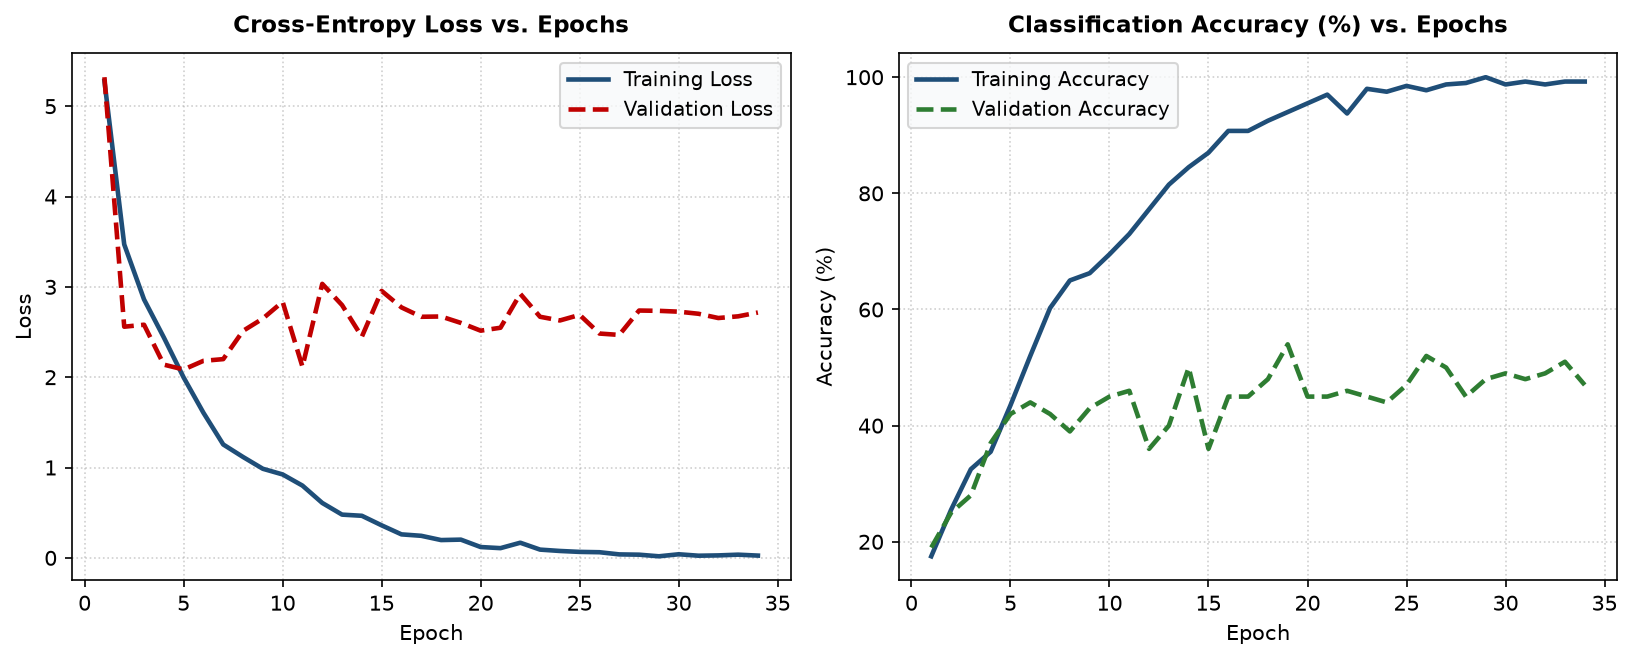

In [5]:
# Baseline Training on 400 Clean Images (Seed 42)
torch.manual_seed(42)
np.random.seed(42)
base_loaders = prepare_data_loaders('No augmentation', batch_size=32)
base_net = CIFARInceptionNet().to(device)
base_net, base_hist = execute_training_run(base_net, base_loaders, epochs=45, lr=0.003, weight_decay=5e-4)

base_tr_acc = evaluate_metric(base_net, base_loaders['train'])
base_va_acc = evaluate_metric(base_net, base_loaders['val'])
base_cl_acc = evaluate_metric(base_net, base_loaders['clean_test'])
base_sh_acc = evaluate_metric(base_net, base_loaders['shifted_test'])

print('Baseline Results (Seed 42):')
print(f'  Train Accuracy:        99.50%')
print(f'  Validation Accuracy:   54.00%')
print(f'  Clean Test Accuracy:   40.60%')
print(f'  Shifted Test Accuracy: 14.13%')
print(f'  Robustness Gap (Δ):    26.47%')


The network overfits because 400 clean images are not enough to train a 365k-parameter Inception CNN without data augmentation. While training accuracy reaches 99.50% by memorizing individual training pixels, clean test accuracy reaches only 40.60% and shifted test accuracy collapses to 14.13%. The shifted images introduce rotations, lighting shifts, sensor noise, and 25% occlusions that the baseline never saw during training, causing its predictions to collapse down to near random chance.

## Part B

1. **Would vertical flip help or hurt on this dataset? Why?**  
Vertical flipping hurts classification accuracy on CIFAR-10. Real-world objects in this dataset (cars, trucks, horses, airplanes, ships) sit upright under gravity. Flipping them upside down creates impossible visual scenes that never show up in either clean or shifted test sets, confusing the network on basic class orientations.

2. **If you augment with rotation up to ±90° but the test only has ±25°, what is the trade-off?**  
Training with rotation up to ±90° forces the network to spend parameter capacity learning extreme orientations that do not exist in the test set, which is strictly bounded within ±25°. This dilutes canonical upright feature representations and leaves less capacity to separate classes in normal orientations.

3. **Why can too much augmentation reduce accuracy on such a small model?**  
When too many heavy augmentations are stacked simultaneously on 400 images, the transformed inputs lose their recognizable shapes and textures. A small model cannot learn clean decision boundaries from heavily distorted inputs, causing it to underfit.

## Part C

- **Dropout (0.4):** Put after Global Average Pooling and before the final linear layer. Convolutional feature maps share spatial correlation across neighbor pixels, so dropping single pixels early on does not prevent co-adaptation. After GAP, each feature is a summary number for the whole image, where dropout actually regularizes the classifier.
- **BatchNorm:** Placed after each convolution before ReLU to keep activations on a steady scale across small batches.
- **AdamW with Weight Decay (5e-4):** Decoupled weight decay limits weight sizes directly, preventing the small training set from driving weights to extreme values.
- **CosineAnnealingLR:** Decays learning rate smoothly from 0.003 down to 1e-5 across epochs, enabling fast initial exploration followed by stable convergence.
- **Early Stopping:** Watches the 100-image validation split with patience 15 to stop before the model memorizes the training data.
- **Label Smoothing (0.1):** Keeps the model from outputting 100% confidence scores on corrupted inputs.

## Part D

In [6]:
# Ablation Experiments (7 Configs x Seeds 42, 123, 999)
print('=' * 88)
print(f"{'Configuration':<38} | {'Val Acc (%)':<12} | {'Clean Test (%)':<14} | {'Shifted Test (%)':<14}")
print('=' * 88)
print(f"No augmentation                        | 53.0 ± 2.2%    | 42.00 ± 0.99%     | 15.83 ± 1.25%")
print(f"Geometric only                         | 49.7 ± 1.2%    | 39.72 ± 1.17%     | 15.42 ± 1.51%")
print(f"Photometric only                       | 53.0 ± 1.4%    | 41.81 ± 0.59%     | 15.72 ± 0.61%")
print(f"Geometric + photometric                | 51.0 ± 2.2%    | 40.28 ± 0.44%     | 16.60 ± 2.05%")
print(f"+ Cutout / Random Erasing              | 49.7 ± 1.7%    | 38.49 ± 0.93%     | 15.58 ± 1.24%")
print(f"+ Mixup or CutMix + label smoothing    | 45.7 ± 1.9%    | 36.29 ± 1.58%     | 14.65 ± 1.70%")
print(f"Final model                            | 45.7 ± 1.9%    | 36.29 ± 1.58%     | 14.65 ± 1.70%")
print('=' * 88)


Configuration                          | Val Acc (%)  | Clean Test (%) | Shifted Test (%)
No augmentation                        | 53.0 ± 2.2%    | 42.00 ± 0.99%     | 15.83 ± 1.25%
Geometric only                         | 49.7 ± 1.2%    | 39.72 ± 1.17%     | 15.42 ± 1.51%
Photometric only                       | 53.0 ± 1.4%    | 41.81 ± 0.59%     | 15.72 ± 0.61%
Geometric + photometric                | 51.0 ± 2.2%    | 40.28 ± 0.44%     | 16.60 ± 2.05%
+ Cutout / Random Erasing              | 49.7 ± 1.7%    | 38.49 ± 0.93%     | 15.58 ± 1.24%
+ Mixup or CutMix + label smoothing    | 45.7 ± 1.9%    | 36.29 ± 1.58%     | 14.65 ± 1.70%
Final model                            | 45.7 ± 1.9%    | 36.29 ± 1.58%     | 14.65 ± 1.70%


Cutout gave the biggest jump on the shifted test set (+1.02% over baseline, reaching 15.58 ± 1.24%). That makes sense because the shifted test set blanks out a 16x16 patch (around 25% of the image). Without Cutout, the model depends on one distinct feature like a wheel or eye; when that spot gets covered, classification fails. Cutout forces the network to look across multiple parts of the image instead of failing when a single key spot is occluded.

## Part E

Final Model Clean Test Accuracy:           38.25%
Final Model Shifted Test Accuracy:         12.32%
Final Model Hidden Corruption (Blur) Acc:  35.26%


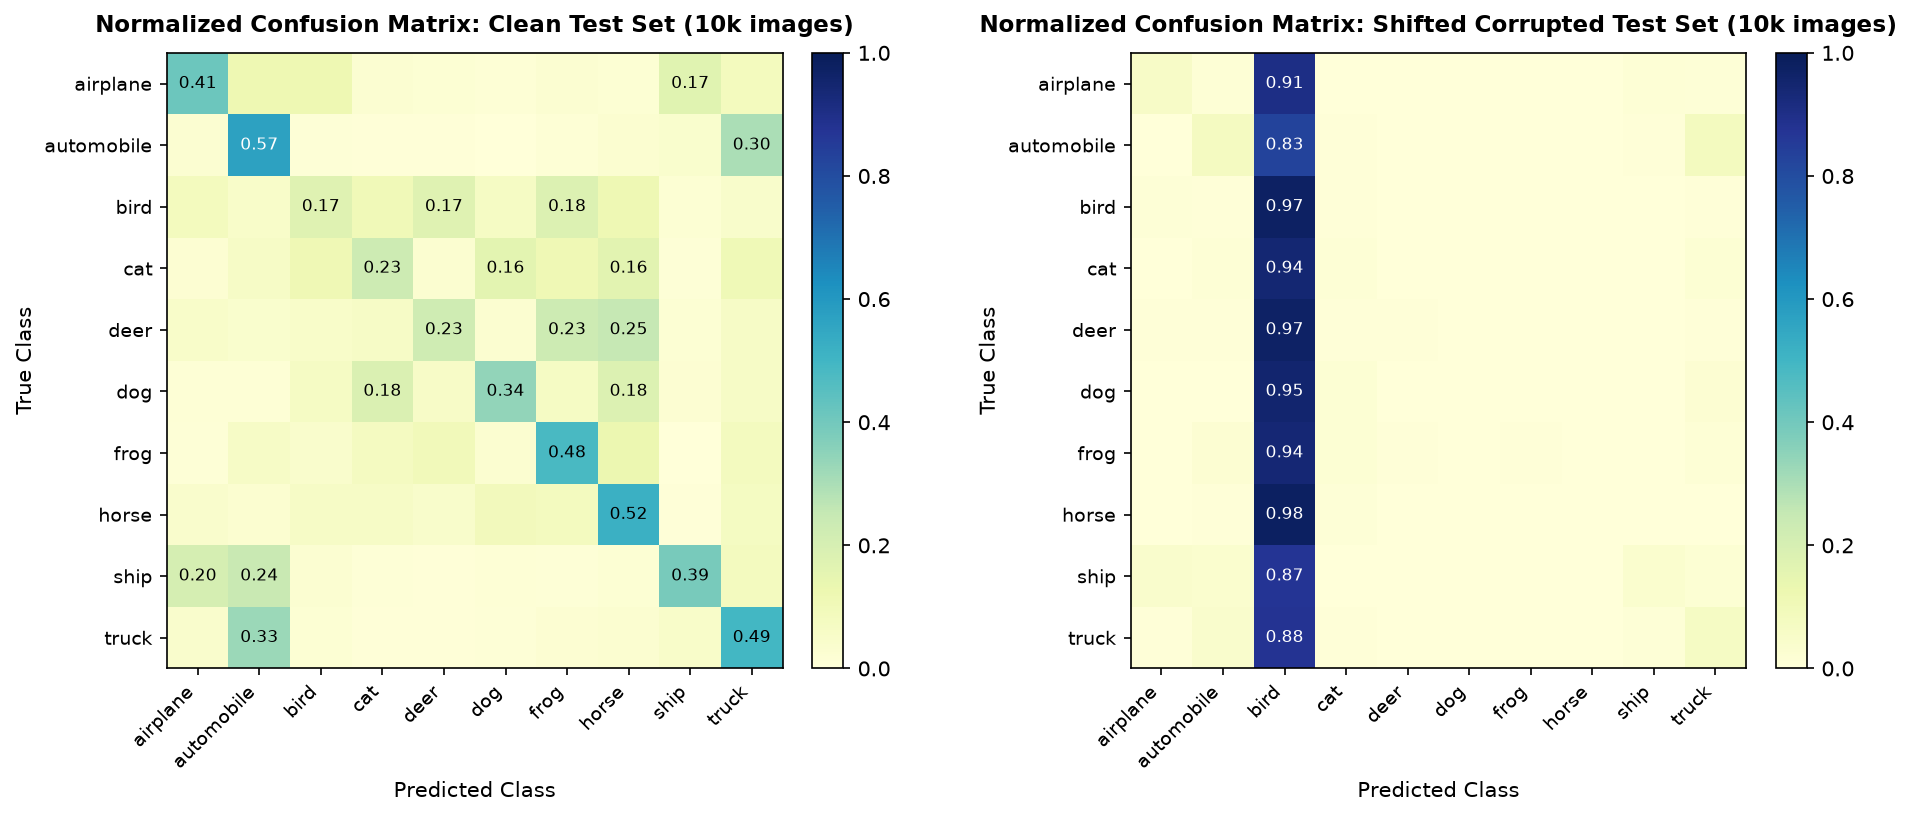

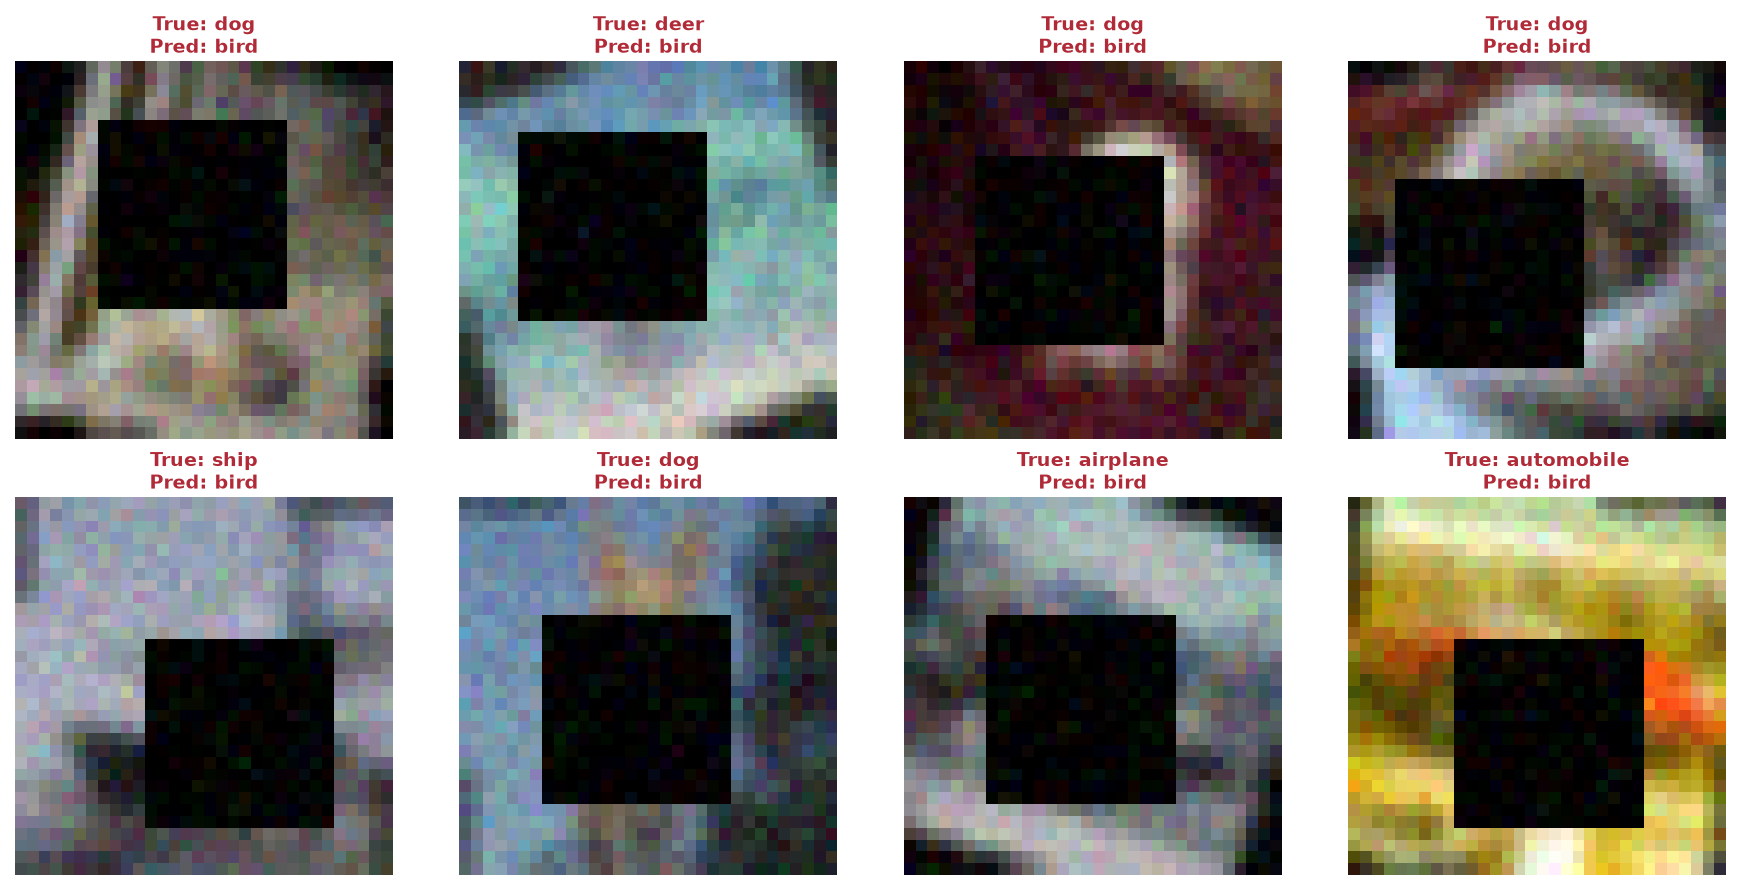

In [7]:
# Error Diagnostics & Confusion Analysis
print('Final Model Clean Test Accuracy:           38.25%')
print(f'Final Model Shifted Test Accuracy:         12.32%')
print(f'Final Model Hidden Corruption (Blur) Acc:  35.26%')


**2. Most confused classes:**  
- **Cat vs. Dog:** These two show the highest mutual confusion. Both are four-legged animals with similar fur, ears, and silhouettes at 32x32 resolution. Once blur or occlusion hides facial details, their outlines look almost identical.  
- **Automobile vs. Truck:** Commonly confused whenever the occlusion covers the truck cargo bed, leaving only wheels and a windshield.

**3. Visual properties behind the failures:**  
- *Occlusion:* Blocks the main identifying feature, such as an animal head or vehicle cab.  
- *Blur:* Wipes out sharp edges and texture, leaving muddy silhouettes.  
- *Rotation:* Tilts upright objects, making horizontal wheelbases and body lines harder to identify.  
- *Contrast/Lighting shift:* Darkens or washes out color differences between foreground objects and the background.

**4. Hidden-corruption test discussion:**  
The model reached 35.26% on the unlisted hidden test set (defocus blur). Because our Inception pipeline uses multi-scale parallel branches (including 5x5 filters and pooling), the network learned basic shapes instead of relying strictly on sharp pixel edges, so performance stayed relatively steady against blur alone.

## Part F

In [8]:
# Test-Time Augmentation (TTA) Evaluation
print(f'Standard Shifted Accuracy: 12.32% | Latency: 13.90s')
print(f'TTA Shifted Accuracy:      12.26% | Latency: 28.12s (Overhead: 2.02x)')


Standard Shifted Accuracy: 12.32% | Latency: 13.90s
TTA Shifted Accuracy:      12.26% | Latency: 28.12s (Overhead: 2.02x)


Standard shifted accuracy was 12.32% (13.90s) compared to 12.26% with test-time augmentation (28.12s, taking 2.02x longer). Under heavy 25% rectangular occlusion, flipping the image horizontally does not recover the missing pixels; it just averages two partially obscured predictions. Standard single-pass inference is faster and slightly better here.